<a href="https://colab.research.google.com/github/dthaissantos/data-science/blob/main/estudo/analise-exploratoria-modelagem-predetiva/analise-vendas-jogos-eletronicos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Video Game Sales with Ratings

#### Este conjunto de dados consolida dados das plataformas VGChatz que reúne informações características de jogos e a Metacritic que reúne as avaliações de jogadores e especialistas.
<p>Com base na descrição e estrutura a base combina duas dimensões sendo elas desempenho comercial e avaliação de qualidade. Mas nos trás problemas de qualidade e representatividade.
<p> O autor informa sobre a ausência de informações contidas que cobrem somente a parte das plataformas e que determinados jogos não possuem todas as avaliações.

## 1 ETAPA — Conhecendo os dados


*   Identificar os campos existentes.
*   Estruturação e qualidade dos dados.
*   Aplicar correções necessárias.



In [ ]:
import pandas as pd

df = pd.read_csv('/content/Video_Games_Sales_as_at_22_Dec_2016.csv')

print("Dimensôes: ", df.shape)
display(df.head())


Dimensôes:  (16719, 16)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB


## Avaliando a completude dos dados
O dataset contém 16.719 registros e 16 variáveis que reúne informações de vendas de jogos eletrônicos e avaliações feitas por usuários e especialistas.
<p> A primeira análise com df.info() identifiquei que possui diferença entre registros preenchidos nas variáveis. Enquanto as colunas de vendas apresentam o preenchimento por completo algumas colunas de avaliações possui uma quantidade considerável de nulos.
<p> Aqui eu quantifiquei os valores por variáveis, identifiquei quais campos apresentam maior comprometimento de completude e abaixo irei investigar se existe padrões associados a esses campos sem preenchimento.

In [ ]:
# Investigação dos nulos

total_registros = len(df)

nulos = pd.DataFrame({
    "Valores nulos": df.isnull().sum(),
    "Porcentagem": ((df.isnull().sum() / total_registros) * 100).round(2)
})

nulos = nulos.sort_values(by="Porcentagem", ascending=False)

display(nulos)

,Valores nulos,Porcentagem
User_Count,9129,54.60
Critic_Count,8582,51.33
Critic_Score,8582,51.33
Rating,6769,40.49
User_Score,6704,40.10
Developer,6623,39.61
Year_of_Release,269,1.61
Publisher,54,0.32
Name,2,0.01
Genre,2,0.01


## Resultado investigado da completude

A análise de completude identificou que as variáveis relacionadas às vendas (NA_Sales, EU_Sales, JP_Sales, Other_Sales e Global_Sales) não apresentam nulos no total dos registros.
<p> Mas, foi identificado que as variáveis relacionadas às avaliações dos jogos apresentam um percentual de ausência elevado. Vamos destacar User_Count (54,60%), Critic_Score e Critic_Count (51,33% cada), além de User_Score (40,10%).
<p> As variáveis de Rating (40,49%) e Developer (39,61%) também apresentam ausências relavantes.
<p>Esses resultados fazem sentido com a limitação informada pelo autor do dataset o qual expoe a falta de cobertura parcial de jogos e plataformas pelo Metacritic.
<p> Identifiquei também que Critic_Score e Critic_Count possue a mesma quantidade de valores nulos, o que irei investigar se essas ausencias possuem semelhanças entre campos.

<p> O dataset apresenta completude elevada nas informações de vendas e limitações relavantes nas variáveis de avaliação. Irei realizar uma investigação complementar para identificar póssíveis impáctos sobre as análises.

In [ ]:
# Comparção entre Critic_Score e Critic_Count

pd.crosstab(
    df['Critic_Score'].isnull(),
    df['Critic_Count'].isnull(),
    margins=True
)

Critic_Count,False,True,All
Critic_Score,,,
False,8137,0,8137
True,0,8582,8582
All,8137,8582,16719


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:

# Investigar nulos de Critic_Score por plataforma

plataformas = df.groupby("Platform")["Critic_Score"].agg(
    Total="size",
    Nulos=lambda x: x.isna().sum()
)

plataformas["Percentual_nulos"] = (
    plataformas["Nulos"] / plataformas["Total"] * 100
).round(2)

display(
    plataformas.sort_values(
        "Percentual_nulos",
        ascending=False
    )
)


,Total,Nulos,Percentual_nulos
Platform,,,
2600,133,133,100.00
3DO,3,3,100.00
GB,98,98,100.00
NES,98,98,100.00
N64,319,319,100.00
GG,1,1,100.00
GEN,29,29,100.00
PCFX,1,1,100.00
NG,12,12,100.00


<p> Decidir segmentar a tabela acima entre 3 grupos, plataformas com 100% de ausência, ausência elevada e a menor taxa de ausência.



In [ ]:
# Classificar as plataformas em três grupos

def classificar_grupo(percentual):
    if percentual == 100:
        return "Grupo 1 - 100% de nulos"
    elif percentual >= 50:
        return "Grupo 2 - 50% a menos de 100%"
    else:
        return "Grupo 3 - Menos de 50%"

plataformas["Grupo"] = plataformas["Percentual_nulos"].apply(classificar_grupo)

display(
    plataformas.sort_values(
        ["Grupo", "Percentual_nulos"],
        ascending=[True, False]
    )
)

,Total,Nulos,Percentual_nulos,Grupo
Platform,,,,
2600,133,133,100.00,Grupo 1 - 100% de nulos
3DO,3,3,100.00,Grupo 1 - 100% de nulos
GB,98,98,100.00,Grupo 1 - 100% de nulos
GEN,29,29,100.00,Grupo 1 - 100% de nulos
GG,1,1,100.00,Grupo 1 - 100% de nulos
N64,319,319,100.00,Grupo 1 - 100% de nulos
NES,98,98,100.00,Grupo 1 - 100% de nulos
NG,12,12,100.00,Grupo 1 - 100% de nulos
PCFX,1,1,100.00,Grupo 1 - 100% de nulos



### Hipóteses sobre a ausência das avaliações dos críticos

| Hipótese | Justificativa | Situação |
|---|---|---|
| H1: A ausência de avaliações está associada ao ano de lançamento. | As plataformas do Grupo 1 possuem jogos lançados entre 1980 e 2002 e apresentam 100% de nulos. | Evidência inicial favorável, mas ainda não confirmada. |
| H2: A ausência está associada à cobertura das plataformas pelo Metacritic. | O autor informa que o Metacritic não cobre todas as plataformas. | Hipótese fundamentada na descrição da fonte, ainda não testada. |
| H3: O ano de lançamento, isoladamente, não explica todas as ausências. | O Nintendo DS apresenta 66,68% de nulos, apesar de pertencer a uma geração posterior ao Nintendo 64. | Indício preliminar; requer comparação entre anos e plataformas. |


In [ ]:

# GRUPO 1 - Plataformas com 100% de nulos

grupo1 = plataformas[
    plataformas["Percentual_nulos"] == 100
]

analise_grupo1 = (
    df[df["Platform"].isin(grupo1.index)]
    .groupby("Platform")
    .agg(
        Total=("Name", "size"),
        Ano_minimo=("Year_of_Release", "min"),
        Ano_mediano=("Year_of_Release", "median"),
        Ano_maximo=("Year_of_Release", "max"),
        Anos_nulos=("Year_of_Release", lambda x: x.isna().sum())
    )
)


display(
    grupo1.join(
        analise_grupo1.drop(columns="Total")
    )
)


,Total,Nulos,Percentual_nulos,Grupo,Ano_minimo,Ano_mediano,Ano_maximo,Anos_nulos
Platform,,,,,,,,
2600,133,133,100.0,Grupo 1 - 100% de nulos,1980.0,1982.0,1989.0,17
3DO,3,3,100.0,Grupo 1 - 100% de nulos,1994.0,1995.0,1995.0,0
GB,98,98,100.0,Grupo 1 - 100% de nulos,1988.0,1997.0,2001.0,1
GEN,29,29,100.0,Grupo 1 - 100% de nulos,1990.0,1993.0,1994.0,0
GG,1,1,100.0,Grupo 1 - 100% de nulos,1992.0,1992.0,1992.0,0
N64,319,319,100.0,Grupo 1 - 100% de nulos,1996.0,1999.0,2002.0,3
NES,98,98,100.0,Grupo 1 - 100% de nulos,1983.0,1986.5,1994.0,0
NG,12,12,100.0,Grupo 1 - 100% de nulos,1993.0,1994.5,1996.0,0
PCFX,1,1,100.0,Grupo 1 - 100% de nulos,1996.0,1996.0,1996.0,0


A análise do Grupo 1 identificou 14 plataformas com 100% de valores nulos na variável Critic_Score.

<p>Ao investigar os anos de lançamento, observei que essas plataformas concentram jogos lançados entre 1980 e 2002, indicando uma possível relação entre o período histórico e a ausência das avaliações dos críticos.

<p>Minha hipótese inicial é que a ausência dessas informações esteja associada às limitações históricas de cobertura e registro das avaliações. Essa hipótese também considera a informação apresentada pelo autor do dataset sobre a cobertura parcial das plataformas pelo Metacritic.

<p>Entretanto, os resultados ainda não permitem afirmar que o ano de lançamento seja a causa das ausências.

<p>Considero que os registros do Grupo 1 não são adequados para análises que dependam de Critic_Score, pois nenhum deles possui essa informação. Contudo, ainda podem contribuir para análises históricas de vendas e plataformas.

<p>Portanto, os registros serão preservados na base original, e sua utilização será definida conforme as variáveis necessárias em cada análise.

In [ ]:

# GRUPO 2 - Plataformas com ausência elevada

grupo2 = plataformas[
    (plataformas["Percentual_nulos"] >= 50) &
    (plataformas["Percentual_nulos"] < 100)
]

analise_grupo2 = (
    df[df["Platform"].isin(grupo2.index)]
    .groupby("Platform")
    .agg(
        Total=("Name", "size"),
        Ano_minimo=("Year_of_Release", "min"),
        Ano_mediano=("Year_of_Release", "median"),
        Ano_maximo=("Year_of_Release", "max"),
        Anos_nulos=("Year_of_Release", lambda x: x.isna().sum())
    )
)

# Unir as informações e reordenar as colunas
resultado_grupo2 = grupo2.join(
    analise_grupo2.drop(columns="Total")
)

resultado_grupo2 = resultado_grupo2[
    [
        "Grupo",
        "Total",
        "Nulos",
        "Percentual_nulos",
        "Ano_minimo",
        "Ano_mediano",
        "Ano_maximo",
        "Anos_nulos"
    ]
]

# Ordenar pelas plataformas com maior percentual de nulos
display(
    resultado_grupo2.sort_values(
        "Percentual_nulos",
        ascending=False
    )
)


,Grupo,Total,Nulos,Percentual_nulos,Ano_minimo,Ano_mediano,Ano_maximo,Anos_nulos
Platform,,,,,,,,
PS,Grupo 2 - 50% a menos de 100%,1197,997,83.29,1994.0,1998.0,2003.0,7
DC,Grupo 2 - 50% a menos de 100%,52,38,73.08,1998.0,2000.0,2008.0,0
PSV,Grupo 2 - 50% a menos de 100%,432,312,72.22,2011.0,2014.0,2017.0,1
3DS,Grupo 2 - 50% a menos de 100%,520,352,67.69,2011.0,2013.0,2016.0,8
DS,Grupo 2 - 50% a menos de 100%,2152,1435,66.68,1985.0,2008.0,2020.0,30
PSP,Grupo 2 - 50% a menos de 100%,1209,747,61.79,2004.0,2009.0,2015.0,16
Wii,Grupo 2 - 50% a menos de 100%,1320,735,55.68,2006.0,2009.0,2016.0,34


A análise do Grupo 2 identificou diferenças importantes na ausência de avaliações entre plataformas com períodos de lançamento distintos.

O PlayStation original apresentou a maior ausência proporcional de `Critic_Score` (83,29%), enquanto o Nintendo DS concentrou a maior quantidade absoluta de registros sem avaliação (1.435).

A comparação entre PlayStation Vita e Nintendo Wii apresentou um contraponto à hipótese inicial de que plataformas mais antigas necessariamente possuem maior ausência. O PSV, com ano mediano de 2014, apresenta 72,22% de nulos, enquanto o Wii, com ano mediano de 2009, apresenta 55,68%.

Essa diferença sugere que o período de lançamento, isoladamente, pode não explicar a disponibilidade das avaliações. Outros fatores, como a cobertura específica das plataformas pelo Metacritic, precisam ser investigados.

Possível inconsistência identificada: também foi observado que o Nintendo DS apresenta ano mínimo de lançamento registrado em 1985, embora o console tenha sido lançado em 2004. Essa divergência pode indicar um erro no ano informado, na identificação da plataforma ou na associação entre o jogo e sua versão. O registro deverá ser investigado posteriormente na avaliação de precisão dos dados, antes de qualquer correção ou exclusão. [fonte](https://pt.wikipedia.org/wiki/Nintendo_DS)

**Conclusão preliminar:** os resultados do Grupo 2 reforçam a necessidade de analisar conjuntamente plataforma e ano de lançamento antes de determinar o mecanismo de ausência ou realizar exclusões de registros.

In [ ]:

# Investigar jogos do Nintendo DS registrados antes de 2004

df[
    (df["Platform"] == "DS") &
    (df["Year_of_Release"] < 2004)
][["Name", "Platform", "Year_of_Release", "Publisher"]]


,Name,Platform,Year_of_Release,Publisher
15959,Strongest Tokyo University Shogi DS,DS,1985.0,Mycom


### Investigação de precisão — Ano de lançamento do Nintendo DS

Ao investigar os registros do Nintendo DS com ano anterior a 2004, identifiquei o jogo *Strongest Tokyo University Shogi DS*, registrado com ano de lançamento de 1985, plataforma DS e publicadora Mycom.

A consulta a fontes externas identificou o jogo sob o título *Saikyou Toudai Shogi DS*, com lançamento no Japão em 10 de maio de 2007, conforme os catálogos GameFAQs e Title Screen.

Essa divergência indica um provável erro no campo `Year_of_Release`. O ano de 2007 será considerado uma correção proposta, sujeita à documentação da fonte utilizada.

O registro será preservado na base original até a etapa de preparação e tratamento dos dados.

**Fontes:** GameFAQs [GameFAQs (catálogo Mainichi Communications)](https://gamefaqs.gamespot.com/games/company/92525-mainichi-communications) e [GameFAQs (catálogo Mainichi Communications) e Title Screen (catálogo Mycom)](https://titlescreen.org/company/ccedn7k3).

In [ ]:

# GRUPO 3 - Plataformas com menos de 50% de nulos

grupo3 = plataformas[
    plataformas["Percentual_nulos"] < 50
]

analise_grupo3 = (
    df[df["Platform"].isin(grupo3.index)]
    .groupby("Platform")
    .agg(
        Total=("Name", "size"),
        Ano_minimo=("Year_of_Release", "min"),
        Ano_mediano=("Year_of_Release", "median"),
        Ano_maximo=("Year_of_Release", "max"),
        Anos_nulos=("Year_of_Release", lambda x: x.isna().sum())
    )
)

# Unir as informações e reordenar as colunas
resultado_grupo3 = grupo3.join(
    analise_grupo3.drop(columns="Total")
)

resultado_grupo3 = resultado_grupo3[
    [
        "Grupo",
        "Total",
        "Nulos",
        "Percentual_nulos",
        "Ano_minimo",
        "Ano_mediano",
        "Ano_maximo",
        "Anos_nulos"
    ]
]

display(
    resultado_grupo3.sort_values(
        "Percentual_nulos",
        ascending=False
    )
)


,Grupo,Total,Nulos,Percentual_nulos,Ano_minimo,Ano_mediano,Ano_maximo,Anos_nulos
Platform,,,,,,,,
GBA,Grupo 3 - Menos de 50%,822,384,46.72,2000.0,2003.0,2007.0,11
PS2,Grupo 3 - Menos de 50%,2161,863,39.94,2000.0,2005.0,2011.0,34
WiiU,Grupo 3 - Menos de 50%,147,57,38.78,2012.0,2013.0,2016.0,0
PS3,Grupo 3 - Menos de 50%,1331,511,38.39,2006.0,2011.0,2016.0,25
PS4,Grupo 3 - Menos de 50%,393,141,35.88,2013.0,2015.0,2017.0,0
XOne,Grupo 3 - Menos de 50%,247,78,31.58,2013.0,2015.0,2016.0,0
X360,Grupo 3 - Menos de 50%,1262,346,27.42,2005.0,2010.0,2016.0,30
PC,Grupo 3 - Menos de 50%,974,259,26.59,1985.0,2010.0,2016.0,17
GC,Grupo 3 - Menos de 50%,556,108,19.42,2001.0,2003.0,2007.0,14


A análise do Grupo 3 identificou as plataformas com menos de 50% de ausência na variável `Critic_Score`.

O Xbox original (XB) apresentou a menor proporção de valores nulos, com 12,01%, apesar de possuir ano mediano de lançamento de 2004. Em comparação, o PlayStation 4, com ano mediano de 2015, apresentou 35,88% de ausência.

Também observei diferenças entre plataformas com períodos semelhantes. O PlayStation 4 e o Xbox One apresentam ano mediano de 2015, mas percentuais de ausência de 35,88% e 31,58%, respectivamente.

O PlayStation 2 apresentou a maior quantidade absoluta de nulos do grupo, com 863 registros, correspondentes a 39,94% dos seus dados.

Esses resultados acrescentam evidências de que a ausência das avaliações não segue uma relação simples e uniforme com o ano de lançamento.

**Conclusão preliminar:** os resultados dos três grupos são compatíveis com a hipótese de que a completude das avaliações depende de características adicionais ao período de lançamento, possivelmente incluindo a cobertura específica das plataformas pelo Metacritic. Entretanto, a causa das ausências ainda não foi demonstrada.

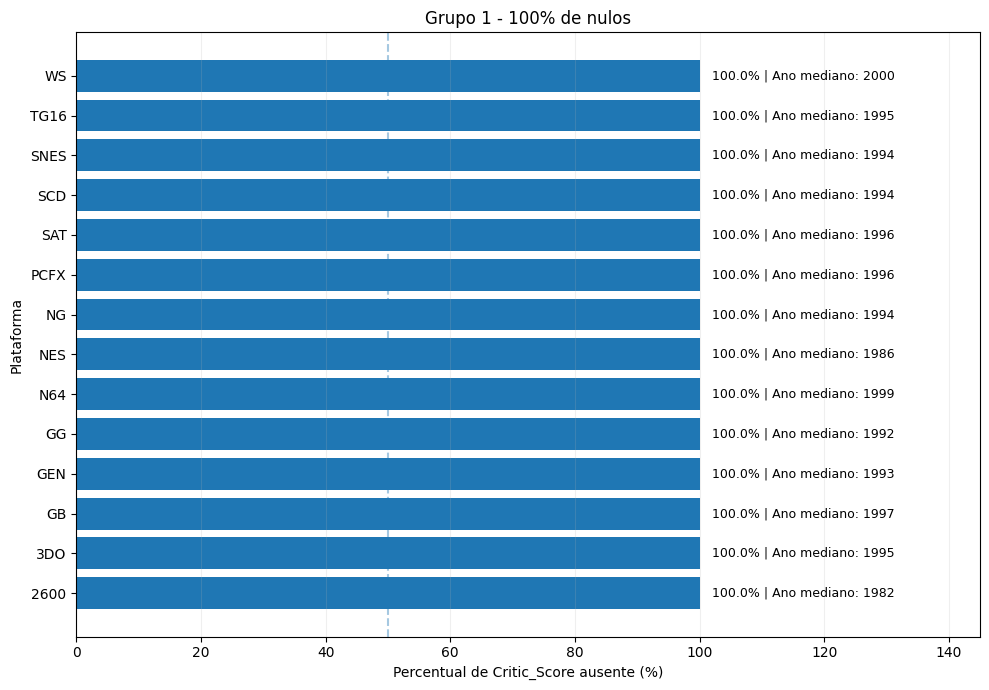

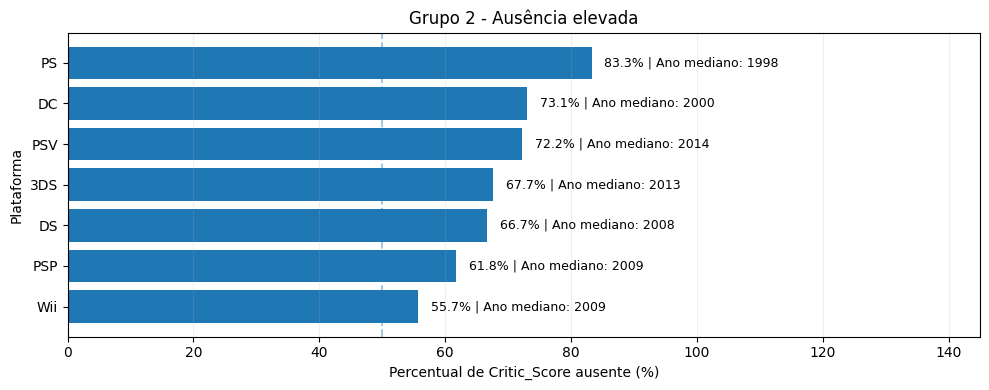

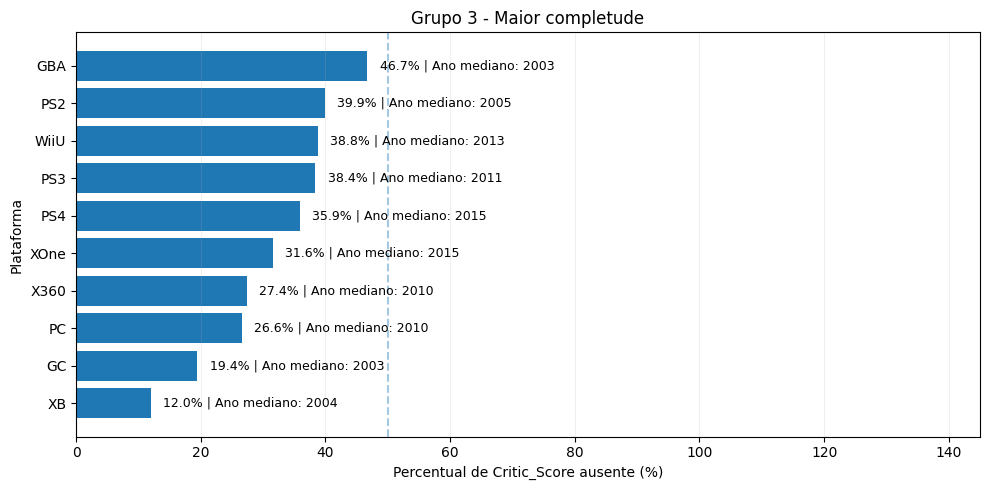

In [ ]:

import matplotlib.pyplot as plt

# Consolidar os resultados dos três grupos
resultado_grupo1 = grupo1.join(
    analise_grupo1.drop(columns="Total")
)

grupos = {
    "Grupo 1 - 100% de nulos": resultado_grupo1,
    "Grupo 2 - Ausência elevada": resultado_grupo2,
    "Grupo 3 - Maior completude": resultado_grupo3
}

# Gerar um gráfico separado para cada grupo
for nome, dados in grupos.items():

    dados = dados.sort_values("Percentual_nulos")

    fig, ax = plt.subplots(
        figsize=(10, max(4, len(dados) * 0.5))
    )

    barras = ax.barh(
        dados.index,
        dados["Percentual_nulos"]
    )

    # Mostrar percentual e ano mediano
    for barra, (_, linha) in zip(barras, dados.iterrows()):

        percentual = linha["Percentual_nulos"]
        ano = linha["Ano_mediano"]

        ax.text(
            percentual + 2,
            barra.get_y() + barra.get_height() / 2,
            f"{percentual:.1f}% | Ano mediano: {ano:.0f}",
            va="center",
            fontsize=9
        )

    ax.set_xlim(0, 145)
    ax.set_xlabel("Percentual de Critic_Score ausente (%)")
    ax.set_ylabel("Plataforma")
    ax.set_title(nome)

    ax.axvline(50, linestyle="--", alpha=0.4)
    ax.grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.show()
